In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','pid1','pid2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s']

In [12]:
df = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all_pid_new.root', "MatchedTree"),'bs!=-9 and bs!=0 and b!=-9 and reject<=0 and rejects<=0 and pts>15')

In [13]:
sum(df[df.b==0]['w'])/sum(df['w'])

0.3709760335566104

In [22]:
sum(df[np.logical_or(df.pid1==22, df.pid2==22)]['w'])/sum(df['w']) # gamma

0.0010950332218428855

In [14]:
sum(df[np.logical_or(df.pid1==111, df.pid2==111)]['w'])/sum(df['w']) # pi0

0.18339955188734397

In [15]:
sum(df[np.logical_or(df.pid1==130, df.pid2==130)]['w'])/sum(df['w']) # K0L

0.016278992377592595

In [16]:
sum(df[np.logical_or(df.pid1==221, df.pid2==221)]['w'])/sum(df['w']) # eta

0.06815129517670993

In [21]:
sum(df[np.logical_or(df.pid1==310, df.pid2==310)]['w'])/sum(df['w']) # K0S

0.04955204845273287

In [18]:
# n
(sum(df[np.logical_or(df.pid1==2112, df.pid2==2112)]['w'])+sum(df[np.logical_or(df.pid1==-2112, df.pid2==-2112)]['w']))/sum(df['w'])

0.033444102358736225

In [19]:
# Lambda
(sum(df[np.logical_or(df.pid1==3122, df.pid2==3122)]['w'])+sum(df[np.logical_or(df.pid1==-3122, df.pid2==-3122)]['w']))/sum(df['w'])

0.025499135508460294

In [32]:
# Sigma
(sum(df[np.logical_or(df.pid1==3212, df.pid2==3212)]['w'])+sum(df[np.logical_or(df.pid1==-3212, df.pid2==-3212)]['w']))/sum(df['w'])

0.012483008444249405

In [23]:
# increase jet pT threshold
sum(df[(df.b==0) & (df.pts>30)]['w'])/sum(df[df.pts>30]['w'])

0.2524198467155052

In [31]:
# increase subleading particle pT threshold
sum(df[(df.b==0) & (df.pt2s>3)]['w'])/sum(df[df.pt2s>3]['w'])

0.28510558044754314

In [ ]:
# end of 04/08/25

In [4]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [5]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [6]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [7]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [9]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [18]:
sum(df[(df.b==0) & (df.pts>20)]['w'])/sum(df[df.pts>20]['w'])

0.32872248739832205

In [80]:
df_neutral_baryon = applyCut(df, 'pid1==2112 or pid2==2112 or pid1==-2112 or pid2==-2112 or pid1==3122 or pid2==3122 or pid1==-3122 or pid2==-3122 or pid1==3212 or pid2==3212 or pid1==-3212 or pid2==-3212 or pid1==3322 or pid2==3322 or pid1==-3322 or pid2==-3322')

In [81]:
sum(df_neutral_baryon['w'])/sum(df['w'])

0.08414857852148609

In [82]:
df_neutral_meson = applyCut(df, 'pid1==111 or pid2==111 or pid1==130 or pid2==130 or pid1==221 or pid2==221 or pid1==310 or pid2==310')

In [83]:
sum(df_neutral_meson['w'])/sum(df['w'])

0.341229447182368

In [84]:
df_neutral_other = applyCut(df, 'pid1==12 or pid2==12 or pid1==22 or pid2==22')

In [85]:
sum(df_neutral_other['w'])/sum(df['w'])

0.001176884504009107

In [15]:
h,x,y = np.histogram2d(df['bs'],df['b'], bins=([-1.5,-0.5,0.5,1.5]), weights=df['w'], density=True)

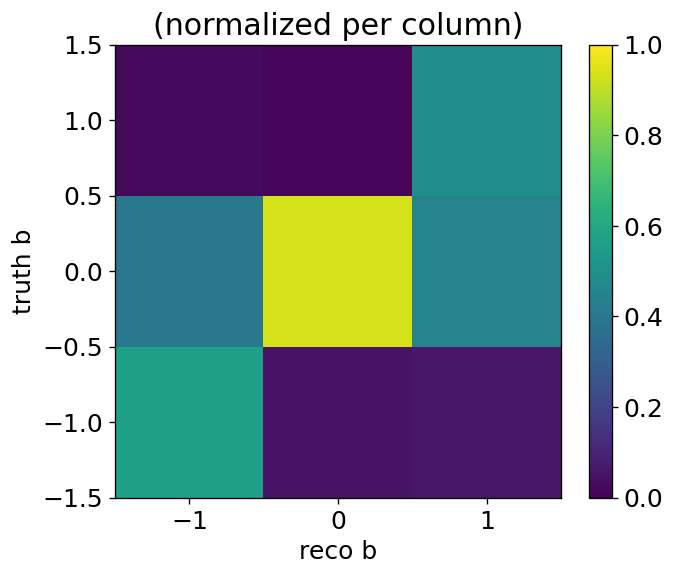

In [16]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5])
plt.pcolormesh([-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5], np.transpose(w))
plt.xlabel('reco b')
plt.ylabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)
plt.clim(0,1)

In [17]:
w

array([[0.57305404, 0.40041254, 0.02653342],
       [0.05041279, 0.93495504, 0.01463217],
       [0.0622307 , 0.44849789, 0.48927141]])

In [48]:
h,x,y = np.histogram2d(df['b'],df['bs'], bins=([-1.5,-0.5,0.5,1.5]), weights=df['w'], density=True)

(-1.5, 1.5)

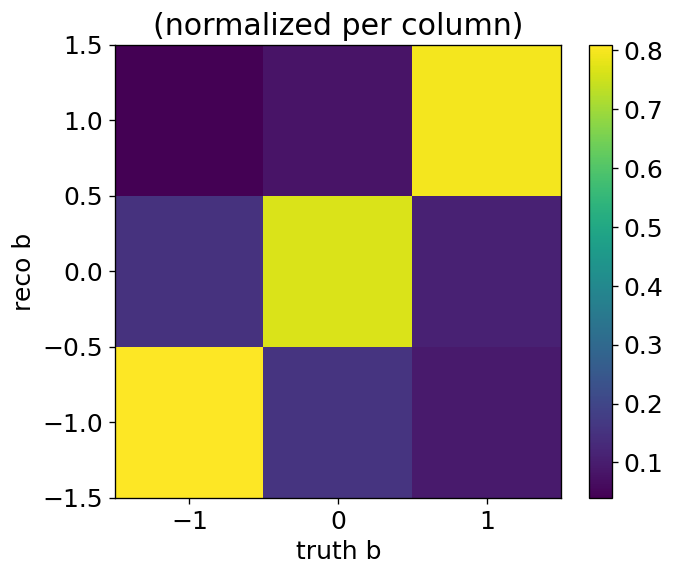

In [49]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5])
plt.pcolormesh([-1.5,-0.5,0.5,1.5],[-1.5,-0.5,0.5,1.5], np.transpose(w))
plt.ylabel('reco b')
plt.xlabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.5,1.5)
plt.ylim(-1.5,1.5)